# Paths, margin, and capital

`PortfolioEvolver` revalues the book along a path. It will not start while the forward curve is deterministic. This notebook builds the same pillars with `roll=sjd.ForwardRoll.FORWARD_VOLATILITY`, then compares an unmargined current-exposure portfolio with a margined one.

A spot path is the forward the book is marked against on each simulation date. Passing the curve's own forwards keeps the book on the expected forward. Monte Carlo then draws normal shocks around that curve. Results come back as dates, headings, and rows from `get_spot_path_detail` and `get_monte_carlo_detail`.

`EE with HP` matches `EE` here. A holding-period (margin lag) offset is a separate evolver constructor and is not used in these notebooks.

`portfolio_validation.ipynb` is the preflight that fails before this forward is in place.

The path stops at the forward settlement. The Asian averaging month is still ahead of that date, so those days stay forwards rather than historic fixes. A rolled fixing curve only receives the simulation dates.


In [1]:
import math
import sys
from datetime import date
from pathlib import Path

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, *_cwd.parents]:
    _notebooks = _candidate / "python" / "notebooks"
    if (_notebooks / "sjd_setup.py").is_file():
        if str(_notebooks) not in sys.path:
            sys.path.insert(0, str(_notebooks))
        break
    if (_candidate / "sjd_setup.py").is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break
else:
    raise RuntimeError("Could not find python/notebooks/sjd_setup.py from " + str(_cwd))

import sjd_setup

sjd = sjd_setup.load_sjd()
print(sjd.__file__)


E:\Code\sjd\python\sjd_runtime\sjd.pyd


## Stochastic market and two capital portfolios


In [2]:
market = sjd_setup.sample_market(sjd, stochastic=True)
assert market["forward"].is_ok(), market["forward"].error_messages()
environment = market["environment"]
credit = sjd_setup.credit_parameters(sjd)
factors = sjd.reg_cap_factors("commodity")

unmargined = sjd.PortfolioB2CEM(
    sjd_setup.sample_contracts(sjd, market["forward"], market)["contracts"],
    factors,
    credit,
    True,
)
agreement = sjd.SimpleMargin(
    market["anchor"],
    True,
    50_000.0,
    True,
    50_000.0,
    10_000.0,
    1_000.0,
)
margined = sjd.PortfolioB2CEM(
    sjd_setup.sample_contracts(sjd, market["forward"], market)["contracts"],
    factors,
    credit,
    True,
    agreement,
)
for portfolio in (unmargined, margined):
    report = portfolio.validate_report(environment)
    assert report.ok, [issue.message for issue in report.issues]

spot_path = [market["forward"].get_forward(day) for day in market["simulation_dates"]]
print("simulation dates", ", ".join(day.isoformat() for day in market["simulation_dates"]))
print("forward path", ", ".join(f"{spot:,.4f}" for spot in spot_path))


simulation dates 2026-09-16, 2026-12-17, 2027-03-16
forward path 17.5000, 17.6328, 17.7623


## Spot path

Call `validate_report` on the evolver before reading a path. That call rolls the curves onto the simulation dates. The first row is the anchor mark-to-market.


In [3]:
def show_detail(title, detail):
    print(f"\n{title}")
    headings = list(detail["headings"])
    print(f"{'Date':<12}" + "".join(f"{name:>14}" for name in headings))
    for day, row in zip(detail["dates"], detail["rows"]):
        print(f"{day:%Y-%m-%d}" + "".join(f"{value:14,.2f}" for value in row))

def evolve(portfolio):
    evolver = sjd.PortfolioEvolver(
        portfolio,
        sjd.SingleFactorEconomicScenarioGenerator(environment),
        market["simulation_dates"],
        portfolio.regulatory_capital(),
    )
    report = evolver.validate_report()
    assert report.ok, [(issue.code, issue.message) for issue in report.issues]
    return evolver

plain = evolve(unmargined)
collateral = evolve(margined)
plain_path = plain.get_spot_path_detail(spot_path)
collateral_path = collateral.get_spot_path_detail(spot_path)
show_detail("Unmargined forward path", plain_path)
show_detail("Margined forward path", collateral_path)

anchor_mtm = unmargined.get_value(environment)
assert math.isclose(plain_path["rows"][0][1], anchor_mtm, rel_tol=1e-8)
assert "Margin" in list(collateral_path["headings"])
assert "Reg Cap" in list(plain_path["headings"])



Unmargined forward path
Date             Spot Path           MtM            EE           NEE    EE with HP   NEE with HP       Reg Cap
2026-09-16         17.50    410,941.59    410,941.59          0.00    410,941.59          0.00    376,664.68
2026-12-17         17.63    431,003.23    431,003.23          0.00    431,003.23          0.00    387,136.86
2027-03-16         17.76    438,422.94    438,422.94          0.00    438,422.94          0.00    248,221.30

Margined forward path
Date             Spot Path           MtM        Margin            EE           NEE    EE with HP   NEE with HP       Reg Cap
2026-09-16         17.50    410,941.59    361,000.00     49,941.59          0.00     49,941.59          0.00    347,784.68
2026-12-17         17.63    431,003.23    382,000.00     49,003.23          0.00     49,003.23          0.00    356,576.86
2027-03-16         17.76    438,422.94    382,000.00     56,422.94          0.00     56,422.94          0.00    217,661.30


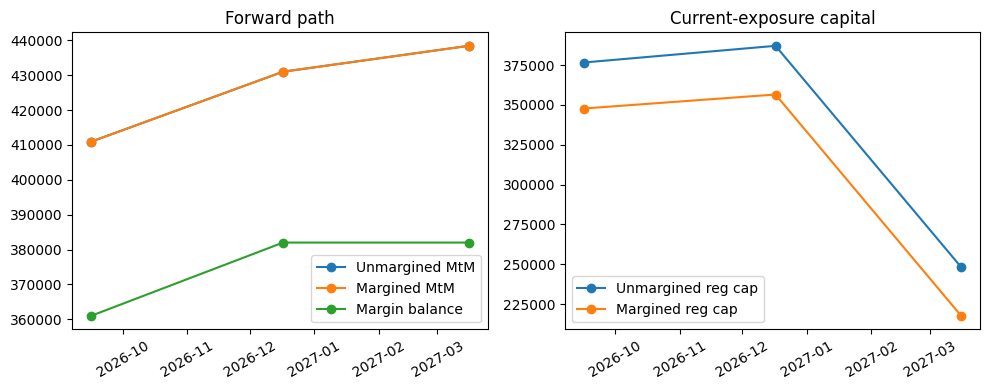

In [4]:
import matplotlib.pyplot as plt

def column(detail, name):
    index = list(detail["headings"]).index(name)
    return [row[index] for row in detail["rows"]]

dates = list(plain_path["dates"])
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(dates, column(plain_path, "MtM"), marker="o", label="Unmargined MtM")
axes[0].plot(dates, column(collateral_path, "MtM"), marker="o", label="Margined MtM")
axes[0].plot(dates, column(collateral_path, "Margin"), marker="o", label="Margin balance")
axes[0].set_title("Forward path")
axes[0].legend()
axes[1].plot(dates, column(plain_path, "Reg Cap"), marker="o", label="Unmargined reg cap")
axes[1].plot(dates, column(collateral_path, "Reg Cap"), marker="o", label="Margined reg cap")
axes[1].set_title("Current-exposure capital")
axes[1].legend()
for axis in axes:
    axis.tick_params(axis="x", rotation=30)
figure.tight_layout()
plt.show()


## Monte Carlo

`run_monte_carlo` draws antithetic pairs. `PFE` is the 95th percentile of positive exposure and `-ve PFE` is the 5th percentile of negative exposure. Fifty paths are enough to see the shape; they are not a production confidence interval.

The margined book's expected exposure is the positive part of `MtM - margin balance`, so it sits below the unmargined expected exposure once collateral has caught up.



Unmargined Monte Carlo
Date              Ave Path       Ave MtM            EE           NEE    EE with HP   NEE with HP           PFE       -ve PFE   PFE with HP-ve PFE with HP       Reg Cap
2026-09-16         17.50    410,941.59    410,941.59          0.00    410,941.59          0.00    410,941.59          0.00    410,941.59          0.00    376,664.68
2026-12-17         17.62    409,425.93    592,188.09   -182,762.16    592,188.09   -182,762.16  1,719,189.59   -828,001.74  1,719,189.59   -828,001.74    309,272.86
2027-03-16         17.74    401,318.74    968,619.81   -567,301.08    968,619.81   -567,301.08  3,537,411.82 -2,505,402.46  3,537,411.82 -2,505,402.46    237,733.02

Margined Monte Carlo
Date              Ave Path       Ave MtM    Ave Margin            EE           NEE    EE with HP   NEE with HP           PFE       -ve PFE   PFE with HP-ve PFE with HP       Reg Cap
2026-09-16         17.50    410,941.59    361,000.00     49,941.59          0.00     49,941.59          0.00 

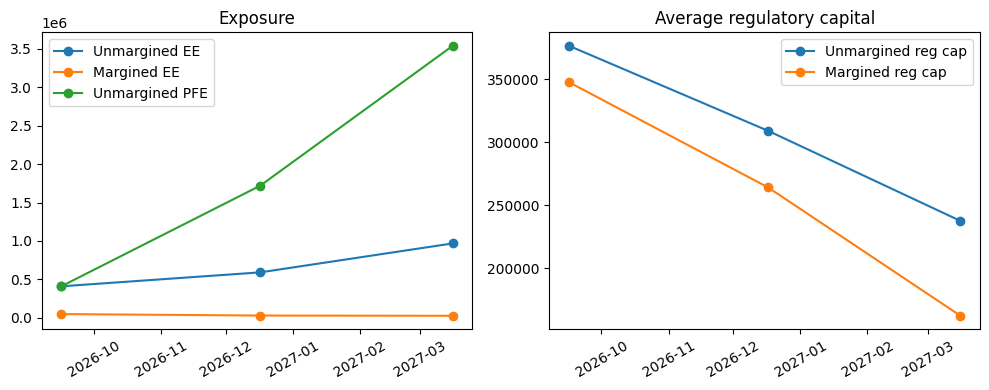

In [5]:
import matplotlib.pyplot as plt

plain.run_monte_carlo(50)
collateral.run_monte_carlo(50)
plain_mc = plain.get_monte_carlo_detail()
collateral_mc = collateral.get_monte_carlo_detail()
show_detail("Unmargined Monte Carlo", plain_mc)
show_detail("Margined Monte Carlo", collateral_mc)
assert "PFE" in list(plain_mc["headings"])
assert "Ave Margin" in list(collateral_mc["headings"])

dates = list(plain_mc["dates"])
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(dates, column(plain_mc, "EE"), marker="o", label="Unmargined EE")
axes[0].plot(dates, column(collateral_mc, "EE"), marker="o", label="Margined EE")
axes[0].plot(dates, column(plain_mc, "PFE"), marker="o", label="Unmargined PFE")
axes[0].set_title("Exposure")
axes[0].legend()
axes[1].plot(dates, column(plain_mc, "Reg Cap"), marker="o", label="Unmargined reg cap")
axes[1].plot(dates, column(collateral_mc, "Reg Cap"), marker="o", label="Margined reg cap")
axes[1].set_title("Average regulatory capital")
axes[1].legend()
for axis in axes:
    axis.tick_params(axis="x", rotation=30)
figure.tight_layout()
plt.show()
